# 🧠 05 — Train Vanilla LSTM (1 chiều)

> **Mục đích:** So sánh với BiLSTM (notebook 03) và Transformer (notebook 04)
>
> **Khác biệt so với BiLSTM:** Dùng LSTM 1 chiều (chỉ đọc tiến), không Bidirectional
>
> **Input:** `data/processed/X_train.npy`, `X_val.npy`, `X_test.npy`, `y_*.npy`
>
> **Output:** `models/lstm_vanilla/best_model.h5`, `training_history.json`

In [1]:
# ==== CELL 1: Cài thư viện ====
import subprocess, sys
pkgs = ['tensorflow', 'numpy', 'scikit-learn', 'matplotlib', 'seaborn']
subprocess.run([sys.executable, '-m', 'pip', 'install', '--quiet'] + pkgs, check=True)
print('Packages OK')

Packages OK


In [2]:
# ==== CELL 2: Import ====
import os, json, warnings
os.environ['TF_CPP_MIN_LOG_LEVEL'] = '2'
warnings.filterwarnings('ignore')

import numpy as np
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers, callbacks
from sklearn.utils.class_weight import compute_class_weight
from sklearn.metrics import classification_report, confusion_matrix
import matplotlib.pyplot as plt
import seaborn as sns

print('TensorFlow:', tf.__version__)
print('GPU:', tf.config.list_physical_devices('GPU') or 'None (CPU mode)')

SEED = 42
tf.random.set_seed(SEED)
np.random.seed(SEED)

TensorFlow: 2.21.0
GPU: None (CPU mode)


In [3]:
# ==== CELL 3: Config ====
BASE = r'd:\University_DUT\Semester7\Hoc_may_ung_dung\Project_CK\ExercisePoseAssessment'
DATA_DIR  = os.path.join(BASE, 'data', 'processed')
MODEL_DIR = os.path.join(BASE, 'models', 'lstm_vanilla')   # Khac notebook 03!
os.makedirs(MODEL_DIR, exist_ok=True)

LABEL_MAP   = {0: 'push-up', 1: 'lateral raise', 2: 'squat', 3: 'pull Up', 4: 'leg raises'}
N_CLASSES   = 5
INPUT_SHAPE = (30, 99)

EPOCHS     = 150
BATCH_SIZE = 32
LR_INIT    = 1e-3
PATIENCE   = 20

BEST_MODEL_PATH = os.path.join(MODEL_DIR, 'best_model.h5')

print(f'Data dir  : {DATA_DIR}')
print(f'Model dir : {MODEL_DIR}')
print(f'Config    : epochs={EPOCHS}, batch={BATCH_SIZE}, lr={LR_INIT}, patience={PATIENCE}')

Data dir  : d:\University_DUT\Semester7\Hoc_may_ung_dung\Project_CK\ExercisePoseAssessment\data\processed
Model dir : d:\University_DUT\Semester7\Hoc_may_ung_dung\Project_CK\ExercisePoseAssessment\models\lstm_vanilla
Config    : epochs=150, batch=32, lr=0.001, patience=20


In [4]:
# ==== CELL 4: Load Data ====
X_train = np.load(os.path.join(DATA_DIR, 'X_train.npy'))
X_val   = np.load(os.path.join(DATA_DIR, 'X_val.npy'))
X_test  = np.load(os.path.join(DATA_DIR, 'X_test.npy'))
y_train = np.load(os.path.join(DATA_DIR, 'y_train.npy'))
y_val   = np.load(os.path.join(DATA_DIR, 'y_val.npy'))
y_test  = np.load(os.path.join(DATA_DIR, 'y_test.npy'))

print('=== DATA LOADED ===')
print(f'X_train : {X_train.shape}  y_train : {y_train.shape}')
print(f'X_val   : {X_val.shape}  y_val   : {y_val.shape}')
print(f'X_test  : {X_test.shape}  y_test  : {y_test.shape}')

cw = compute_class_weight('balanced', classes=np.unique(y_train), y=y_train)
CLASS_WEIGHT = dict(enumerate(cw))
print('\nClass weights:', {LABEL_MAP[k]: round(v, 3) for k, v in CLASS_WEIGHT.items()})

=== DATA LOADED ===
X_train : (19224, 30, 99)  y_train : (19224,)
X_val   : (1247, 30, 99)  y_val   : (1247,)
X_test  : (1061, 30, 99)  y_test  : (1061,)

Class weights: {'push-up': np.float64(0.903), 'lateral raise': np.float64(0.809), 'squat': np.float64(0.826), 'pull Up': np.float64(1.208), 'leg raises': np.float64(1.615)}


In [5]:
# ==== CELL 5: Build Vanilla LSTM Model ====
# KHAC BIET chinh so voi notebook 03:
#   Notebook 03: Bidirectional(LSTM(...)) -> doc 2 chieu
#   Notebook 05: LSTM(...)               -> doc 1 chieu (tien)

def build_lstm_vanilla(input_shape=(30, 99), n_classes=5, lr=1e-3):
    """Vanilla LSTM 1 chieu — baseline de so sanh voi BiLSTM."""
    inp = keras.Input(shape=input_shape, name='input')

    # Layer 1: LSTM 1 chieu (256 units, return_sequences=True)
    # BiLSTM 128 units = 256 total -> dung 256 units LSTM cho fair comparison
    x = layers.LSTM(
        256, return_sequences=True,
        kernel_regularizer=keras.regularizers.l2(1e-4),
        name='lstm_1'
    )(inp)
    x = layers.BatchNormalization()(x)
    x = layers.Dropout(0.3)(x)

    # Layer 2: LSTM 1 chieu (128 units, return_sequences=False)
    x = layers.LSTM(
        128, return_sequences=False,
        kernel_regularizer=keras.regularizers.l2(1e-4),
        name='lstm_2'
    )(x)
    x = layers.BatchNormalization()(x)
    x = layers.Dropout(0.3)(x)

    # Dense head (giong het notebook 03)
    x = layers.Dense(128, activation='relu', kernel_regularizer=keras.regularizers.l2(1e-4))(x)
    x = layers.Dropout(0.3)(x)
    x = layers.Dense(64, activation='relu')(x)
    x = layers.Dropout(0.2)(x)
    out = layers.Dense(n_classes, activation='softmax', name='output')(x)

    model = keras.Model(inp, out, name='LSTM_Vanilla')
    model.compile(
        optimizer=keras.optimizers.Adam(lr),
        loss='sparse_categorical_crossentropy',
        metrics=['accuracy']
    )
    return model


model = build_lstm_vanilla(INPUT_SHAPE, N_CLASSES, LR_INIT)
model.summary()
print(f'\nTotal params: {model.count_params():,}')

Model: "LSTM_Vanilla"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input (InputLayer)              │ (None, 30, 99)         │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lstm_1 (LSTM)                   │ (None, 30, 256)        │       364,544 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 30, 256)        │         1,024 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 30, 256)        │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lstm_2 (LSTM)                   │ (None, 128)            │       197,120 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_1           │ (None, 128)            │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │        16,512 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_2 (Dropout)             │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 64)             │         8,256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_3 (Dropout)             │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ output (Dense)                  │ (None, 5)              │           325 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 588,293 (2.24 MB)

 Trainable params: 587,525 (2.24 MB)

 Non-trainable params: 768 (3.00 KB)


Total params: 588,293


In [6]:
# ==== CELL 6: Callbacks ====
cb_list = [
    callbacks.EarlyStopping(
        monitor='val_accuracy', patience=PATIENCE,
        restore_best_weights=True, verbose=1
    ),
    callbacks.ReduceLROnPlateau(
        monitor='val_loss', factor=0.5, patience=10,
        min_lr=1e-6, verbose=1
    ),
    callbacks.ModelCheckpoint(
        BEST_MODEL_PATH, monitor='val_accuracy',
        save_best_only=True, verbose=1
    ),
    callbacks.CSVLogger(os.path.join(MODEL_DIR, 'train_log.csv')),
]
print('Callbacks ready')
print(f'Best model will be saved to: {BEST_MODEL_PATH}')

Callbacks ready
Best model will be saved to: d:\University_DUT\Semester7\Hoc_may_ung_dung\Project_CK\ExercisePoseAssessment\models\lstm_vanilla\best_model.h5


In [7]:
# ==== CELL 7: Train ====
print('START TRAINING LSTM VANILLA')
print(f'Train: {len(X_train):,} sequences | Val: {len(X_val):,} sequences')
print(f'Epochs: {EPOCHS} (EarlyStopping patience={PATIENCE})')
print('=' * 50)

history = model.fit(
    X_train, y_train,
    validation_data = (X_val, y_val),
    epochs          = EPOCHS,
    batch_size      = BATCH_SIZE,
    class_weight    = CLASS_WEIGHT,
    callbacks       = cb_list,
    verbose         = 1
)
print('\nTraining done!')

START TRAINING LSTM VANILLA
Train: 19,224 sequences | Val: 1,247 sequences
Epochs: 150 (EarlyStopping patience=20)
Epoch 1/150
600/601 ━━━━━━━━━━━━━━━━━━━━ 0s 38ms/step - accuracy: 0.8337 - loss: 0.5569
Epoch 1: val_accuracy improved from None to 0.79631, saving model to d:\University_DUT\Semester7\Hoc_may_ung_dung\Project_CK\ExercisePoseAssessment\models\lstm_vanilla\best_model.h5


601/601 ━━━━━━━━━━━━━━━━━━━━ 27s 40ms/step - accuracy: 0.9191 - loss: 0.3403 - val_accuracy: 0.7963 - val_loss: 1.2208 - learning_rate: 0.0010
Epoch 2/150
601/601 ━━━━━━━━━━━━━━━━━━━━ 0s 36ms/step - accuracy: 0.9690 - loss: 0.1888
Epoch 2: val_accuracy did not improve from 0.79631
601/601 ━━━━━━━━━━━━━━━━━━━━ 23s 37ms/step - accuracy: 0.9764 - loss: 0.1653 - val_accuracy: 0.7915 - val_loss: 1.4046 - learning_rate: 0.0010
Epoch 3/150
601/601 ━━━━━━━━━━━━━━━━━━━━ 0s 39ms/step - accuracy: 0.9869 - loss: 0.1286
Epoch 3: val_accuracy improved from 0.79631 to 0.81796, saving model to d:\University_DUT\Semester7\Hoc_may_ung_dung\Project_CK\ExercisePoseAssessment\models\lstm_vanilla\best_model.h5


601/601 ━━━━━━━━━━━━━━━━━━━━ 24s 40ms/step - accuracy: 0.9847 - loss: 0.1371 - val_accuracy: 0.8180 - val_loss: 1.3673 - learning_rate: 0.0010
Epoch 4/150
600/601 ━━━━━━━━━━━━━━━━━━━━ 0s 38ms/step - accuracy: 0.9887 - loss: 0.1242
Epoch 4: val_accuracy did not improve from 0.81796
601/601 ━━━━━━━━━━━━━━━━━━━━ 24s 40ms/step - accuracy: 0.9900 - loss: 0.1171 - val_accuracy: 0.7731 - val_loss: 1.6356 - learning_rate: 0.0010
Epoch 5/150
600/601 ━━━━━━━━━━━━━━━━━━━━ 0s 39ms/step - accuracy: 0.9890 - loss: 0.1215
Epoch 5: val_accuracy did not improve from 0.81796
601/601 ━━━━━━━━━━━━━━━━━━━━ 24s 40ms/step - accuracy: 0.9906 - loss: 0.1137 - val_accuracy: 0.7650 - val_loss: 2.0815 - learning_rate: 0.0010
Epoch 6/150
601/601 ━━━━━━━━━━━━━━━━━━━━ 0s 35ms/step - accuracy: 0.9954 - loss: 0.0947
Epoch 6: val_accuracy did not improve from 0.81796
601/601 ━━━━━━━━━━━━━━━━━━━━ 22s 37ms/step - accuracy: 0.9939 - loss: 0.0997 - val_accuracy: 0.7947 - val_loss: 1.6760 - learning_rate: 0.0010
Epoch 7/150

601/601 ━━━━━━━━━━━━━━━━━━━━ 21s 34ms/step - accuracy: 0.9963 - loss: 0.0921 - val_accuracy: 0.8268 - val_loss: 1.2081 - learning_rate: 0.0010
Epoch 9/150
601/601 ━━━━━━━━━━━━━━━━━━━━ 0s 33ms/step - accuracy: 0.9881 - loss: 0.1242
Epoch 9: val_accuracy did not improve from 0.82678
601/601 ━━━━━━━━━━━━━━━━━━━━ 21s 34ms/step - accuracy: 0.9920 - loss: 0.1110 - val_accuracy: 0.8051 - val_loss: 2.0332 - learning_rate: 0.0010
Epoch 10/150
601/601 ━━━━━━━━━━━━━━━━━━━━ 0s 33ms/step - accuracy: 0.9941 - loss: 0.1064
Epoch 10: val_accuracy improved from 0.82678 to 0.85004, saving model to d:\University_DUT\Semester7\Hoc_may_ung_dung\Project_CK\ExercisePoseAssessment\models\lstm_vanilla\best_model.h5


601/601 ━━━━━━━━━━━━━━━━━━━━ 21s 35ms/step - accuracy: 0.9937 - loss: 0.1078 - val_accuracy: 0.8500 - val_loss: 1.3780 - learning_rate: 0.0010
Epoch 11/150
601/601 ━━━━━━━━━━━━━━━━━━━━ 0s 33ms/step - accuracy: 0.9971 - loss: 0.0881
Epoch 11: val_accuracy did not improve from 0.85004
601/601 ━━━━━━━━━━━━━━━━━━━━ 20s 34ms/step - accuracy: 0.9928 - loss: 0.1007 - val_accuracy: 0.8316 - val_loss: 1.3820 - learning_rate: 0.0010
Epoch 12/150
601/601 ━━━━━━━━━━━━━━━━━━━━ 0s 32ms/step - accuracy: 0.9917 - loss: 0.1041
Epoch 12: val_accuracy did not improve from 0.85004
601/601 ━━━━━━━━━━━━━━━━━━━━ 20s 34ms/step - accuracy: 0.9932 - loss: 0.1009 - val_accuracy: 0.8244 - val_loss: 1.8170 - learning_rate: 0.0010
Epoch 13/150
601/601 ━━━━━━━━━━━━━━━━━━━━ 0s 33ms/step - accuracy: 0.9923 - loss: 0.1125
Epoch 13: val_accuracy did not improve from 0.85004
601/601 ━━━━━━━━━━━━━━━━━━━━ 21s 34ms/step - accuracy: 0.9933 - loss: 0.1093 - val_accuracy: 0.8027 - val_loss: 1.6776 - learning_rate: 0.0010
Epoch

In [8]:
# ==== CELL 8: Luu training history ====
hist_path = os.path.join(MODEL_DIR, 'training_history.json')
with open(hist_path, 'w') as f:
    json.dump({k: [float(v) for v in vals]
               for k, vals in history.history.items()}, f, indent=2)
print(f'Saved: {hist_path}')

val_acc  = history.history['val_accuracy']
best_ep  = int(max(range(len(val_acc)), key=lambda i: val_acc[i])) + 1
best_va  = max(val_acc)
print(f'Best epoch      : {best_ep}')
print(f'Best val_acc    : {best_va:.4f} ({best_va*100:.2f}%)')
print(f'Total epochs    : {len(val_acc)}')

Saved: d:\University_DUT\Semester7\Hoc_may_ung_dung\Project_CK\ExercisePoseAssessment\models\lstm_vanilla\training_history.json
Best epoch      : 10
Best val_acc    : 0.8500 (85.00%)
Total epochs    : 30


In [9]:
# ==== CELL 9: Evaluate tren Test Set ====
print('Loading best model...')
best_model = keras.models.load_model(BEST_MODEL_PATH)

test_loss, test_acc = best_model.evaluate(X_test, y_test, verbose=0)
print(f'Test Loss    : {test_loss:.4f}')
print(f'Test Accuracy: {test_acc:.4f} ({test_acc*100:.2f}%)')

y_pred  = np.argmax(best_model.predict(X_test, verbose=0), axis=1)
labels  = [LABEL_MAP[i] for i in range(N_CLASSES)]

print('\n=== Classification Report ===')
print(classification_report(y_test, y_pred, target_names=labels))

Loading best model...
Test Loss    : 1.5122
Test Accuracy: 0.8435 (84.35%)

=== Classification Report ===
               precision    recall  f1-score   support

      push-up       0.98      0.97      0.97       289
lateral raise       0.78      0.79      0.79       171
        squat       0.77      0.85      0.81       238
      pull Up       0.79      0.99      0.88       149
   leg raises       0.85      0.60      0.71       214

     accuracy                           0.84      1061
    macro avg       0.83      0.84      0.83      1061
 weighted avg       0.85      0.84      0.84      1061



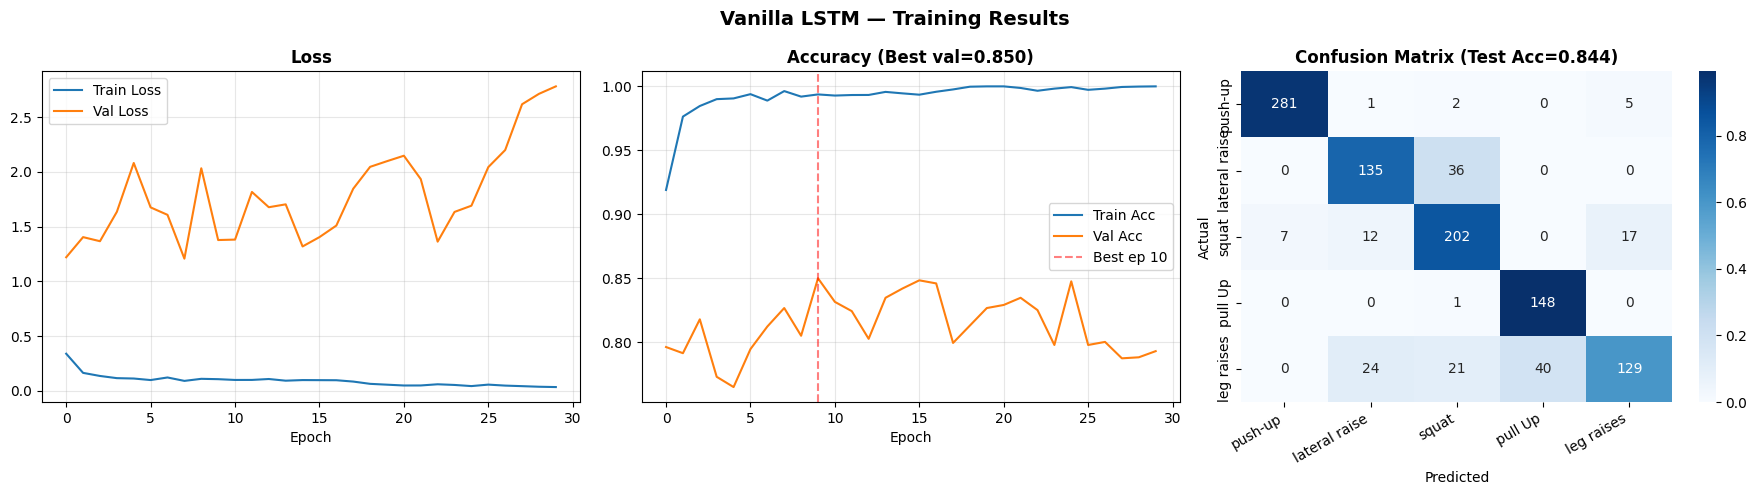

Saved: d:\University_DUT\Semester7\Hoc_may_ung_dung\Project_CK\ExercisePoseAssessment\models\lstm_vanilla\training_results.png


In [10]:
# ==== CELL 10: Plot + Save ====
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

# Loss curve
ax = axes[0]
ax.plot(history.history['loss'],     label='Train Loss')
ax.plot(history.history['val_loss'], label='Val Loss')
ax.set_title('Loss', fontweight='bold'); ax.set_xlabel('Epoch')
ax.legend(); ax.grid(True, alpha=0.3)

# Accuracy curve
ax = axes[1]
ax.plot(history.history['accuracy'],     label='Train Acc')
ax.plot(history.history['val_accuracy'], label='Val Acc')
ax.axvline(best_ep - 1, color='red', linestyle='--', alpha=0.5, label=f'Best ep {best_ep}')
ax.set_title(f'Accuracy (Best val={best_va:.3f})', fontweight='bold')
ax.set_xlabel('Epoch'); ax.legend(); ax.grid(True, alpha=0.3)

# Confusion matrix
cm = confusion_matrix(y_test, y_pred)
cm_norm = cm.astype(float) / cm.sum(axis=1, keepdims=True)
sns.heatmap(cm_norm, annot=cm, fmt='d', cmap='Blues',
            xticklabels=labels, yticklabels=labels, ax=axes[2])
axes[2].set_title(f'Confusion Matrix (Test Acc={test_acc:.3f})', fontweight='bold')
axes[2].set_xlabel('Predicted'); axes[2].set_ylabel('Actual')
plt.setp(axes[2].get_xticklabels(), rotation=30, ha='right')

plt.suptitle('Vanilla LSTM — Training Results', fontsize=14, fontweight='bold')
plt.tight_layout()
png_path = os.path.join(MODEL_DIR, 'training_results.png')
plt.savefig(png_path, dpi=120, bbox_inches='tight')
plt.show()
print(f'Saved: {png_path}')

In [11]:
# ==== CELL 11: Luu model summary ====
summary_path = os.path.join(MODEL_DIR, 'model_summary.json')
with open(summary_path, 'w') as f:
    json.dump({
        'model_name'   : 'LSTM_Vanilla',
        'architecture' : '2-layer Vanilla LSTM (1-directional)',
        'total_params' : int(model.count_params()),
        'best_epoch'   : best_ep,
        'best_val_acc' : float(best_va),
        'test_accuracy': float(test_acc),
        'test_loss'    : float(test_loss),
        'config': {
            'epochs': EPOCHS, 'batch_size': BATCH_SIZE,
            'lr_init': LR_INIT, 'patience': PATIENCE,
            'lstm_units': [256, 128],
            'dense_units': [128, 64],
            'dropout': [0.3, 0.3, 0.3, 0.2]
        }
    }, f, indent=2)
print(f'Saved: {summary_path}')

print()
print('=' * 55)
print('  VANILLA LSTM TRAINING COMPLETE')
print('=' * 55)
print(f'  Model dir    : {MODEL_DIR}')
print(f'  Best val acc : {best_va:.4f} ({best_va*100:.2f}%)')
print(f'  Test accuracy: {test_acc:.4f} ({test_acc*100:.2f}%)')
print()
print('=> Tiep theo: Chay notebook 06_comparison.ipynb de so sanh ca 3 model')

Saved: d:\University_DUT\Semester7\Hoc_may_ung_dung\Project_CK\ExercisePoseAssessment\models\lstm_vanilla\model_summary.json

  VANILLA LSTM TRAINING COMPLETE
  Model dir    : d:\University_DUT\Semester7\Hoc_may_ung_dung\Project_CK\ExercisePoseAssessment\models\lstm_vanilla
  Best val acc : 0.8500 (85.00%)
  Test accuracy: 0.8435 (84.35%)

=> Tiep theo: Chay notebook 06_comparison.ipynb de so sanh ca 3 model
